In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load Data
file_path = glob.glob(r"C:\Users\Vandana\Downloads\WA_Fn*.csv")[0]
df = pd.read_csv(file_path)

# 2. Clean the data (same as Project 1)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 3. Select only the numerical features for clustering
X = df[['tenure', 'MonthlyCharges', 'TotalCharges']]

print("Data shape for clustering:", X.shape)
X.head()

Data shape for clustering: (7043, 3)


,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


In [3]:
# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Data (first 5 rows):")
print(X_scaled[:5])

Scaled Data (first 5 rows):
[[-1.27744458 -1.16032292 -0.99261052]
 [ 0.06632742 -0.25962894 -0.17216471]
 [-1.23672422 -0.36266036 -0.9580659 ]
 [ 0.51425142 -0.74653546 -0.19367238]
 [-1.23672422  0.19736523 -0.93887444]]


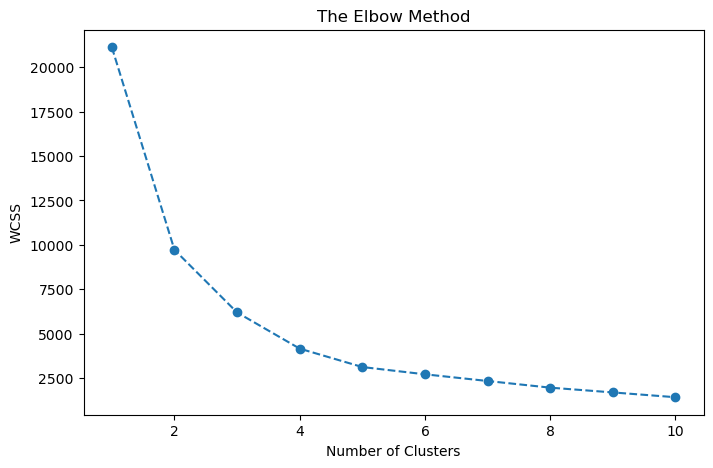

In [4]:
wcss = [] # Within-Cluster Sum of Square

# Try 1 to 10 clusters
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

In [5]:
# Train K-Means with 3 clusters (Change this to 4 if your elbow chart shows the bend at 4)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)

# Fit and predict the cluster for each customer
clusters = kmeans.fit_predict(X_scaled)

# Add the cluster labels back to our original dataframe
df['Cluster'] = clusters

print("Customer count per cluster:")
print(df['Cluster'].value_counts())

Customer count per cluster:
Cluster
0    2681
1    2201
2    2161
Name: count, dtype: int64


In [6]:
# Group by the cluster and calculate the mean
cluster_summary = df.groupby('Cluster')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean()
print(cluster_summary)

            tenure  MonthlyCharges  TotalCharges
Cluster                                         
0        13.256994       75.039276   1032.294237
1        58.559291       89.680032   5245.050704
2        29.411846       26.631444    807.140791


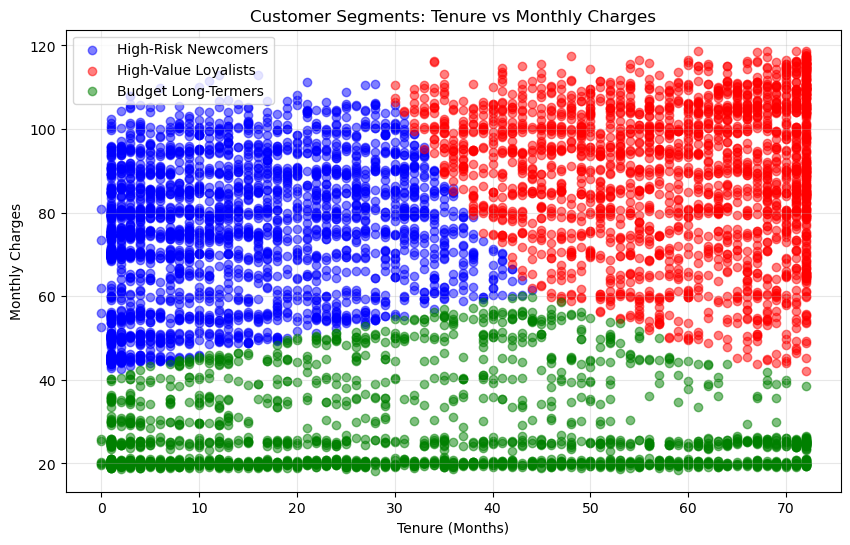

In [7]:
# Visualize the clusters
plt.figure(figsize=(10, 6))

# Plot Cluster 0 (Blue)
plt.scatter(df[df['Cluster'] == 0]['tenure'], df[df['Cluster'] == 0]['MonthlyCharges'], 
            c='blue', label='High-Risk Newcomers', alpha=0.5)

# Plot Cluster 1 (Red)
plt.scatter(df[df['Cluster'] == 1]['tenure'], df[df['Cluster'] == 1]['MonthlyCharges'], 
            c='red', label='High-Value Loyalists', alpha=0.5)

# Plot Cluster 2 (Green)
plt.scatter(df[df['Cluster'] == 2]['tenure'], df[df['Cluster'] == 2]['MonthlyCharges'], 
            c='green', label='Budget Long-Termers', alpha=0.5)

plt.title('Customer Segments: Tenure vs Monthly Charges')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')
plt.legend()
plt.grid(True, alpha=0.3)

# Save the image for GitHub
plt.savefig('cluster_scatter.png', bbox_inches='tight')
plt.show()

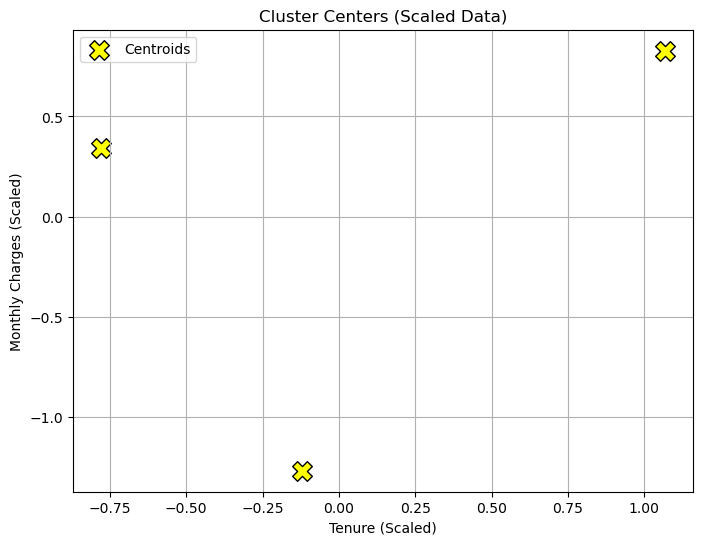

In [8]:
# Plot the cluster centers
plt.figure(figsize=(8, 6))
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=200, c='yellow', label='Centroids', edgecolors='black', marker='X')

plt.title('Cluster Centers (Scaled Data)')
plt.xlabel('Tenure (Scaled)')
plt.ylabel('Monthly Charges (Scaled)')
plt.legend()
plt.grid(True)
plt.show()